In [1]:
import pandas as pd
import statsmodels.api as sm

from sklearn.model_selection import train_test_split

df = pd.read_csv("UrbanCabFare.csv")

features = [
    "Hour_of_Day",
    "Distance_km",
    "Demand_Supply_Ratio",
    "Trip_Duration",
    "Surge_Multiplier"
]

X = df[features]
y = df["Final_Fare"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train_ols = sm.add_constant(X_train)

ols_model = sm.OLS(y_train, X_train_ols).fit()

ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             Final_Fare   R-squared:                       0.930
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                     2098.
Date:                Tue, 25 Aug 2026   Prob (F-statistic):               0.00
Time:                        12:43:44   Log-Likelihood:                -4313.0
No. Observations:                 800   AIC:                             8638.
Df Residuals:                     794   BIC:                             8666.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                -313.1471      9.549    -32.792      0.000    -331.892    -294.402
Hour_of_Day             0.0460      0.264      0.174      0.862      -0.473       0.565
Distance_km            16.8501      0.601     28.046      0.000      15.671      18.029
Demand_Supply_Ratio    -0.5753      0.462     -1.244      0.214      -1.483       0.332
Trip_Duration           0.2527      0.208      1.217      0.224      -0.155       0.660
Surge_Multiplier      257.7125      6.272     41.091      0.000     245.401     270.024
==============================================================================
Omnibus:                        4.798   Durbin-Watson:                   1.971
Prob(Omnibus):                  0.091   Jarque-Bera (JB):                4.885
Skew:                           0.182   Prob(JB):                       0.0870
Kurtosis:                       2.881   Cond. No.                         383.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [5]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X_train)

vif_table = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_table

,Feature,VIF
0,const,25.672045
1,Hour_of_Day,1.007675
2,Distance_km,9.523921
3,Demand_Supply_Ratio,1.318063
4,Trip_Duration,9.554682
5,Surge_Multiplier,1.316845


In [6]:
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

residuals = ols_model.resid

# Breusch-Pagan
bp = het_breuschpagan(residuals, X_train_ols)

# Ramsey RESET
reset = linear_reset(
    ols_model,
    power=2,
    use_f=True
)

print(f"Breusch-Pagan p-value: {bp[1]:.6f}")
print(f"RESET p-value:         {reset.pvalue:.6f}")

Breusch-Pagan p-value: 0.000062
RESET p-value:         0.000000


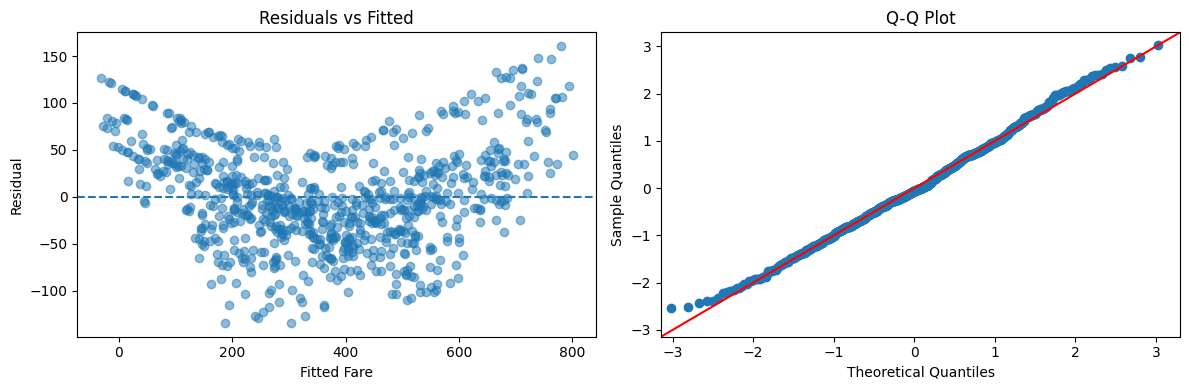

In [7]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

fitted = ols_model.fittedvalues
residuals = ols_model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(fitted, residuals, alpha=0.5)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Fitted Fare")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Fitted")

sm.qqplot(residuals, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q Plot")

plt.tight_layout()
plt.show()